# Biomass LA2 product Congo basin vs CCI Biomass

Objetive: Establish an area of analisis based on the valid pixel available from the AGB LA2 map and the CCI biomass products footprint

### 1. Packages and Libraries

In [ ]:
%pip install aiohttp requests

from shapely.geometry import Polygon, box
from rasterio.windows import Window
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
from pystac_client import Client
from folium import GeoJson
import geopandas as gpd
from io import BytesIO
import rasterio as rio
from tqdm import tqdm
from PIL import Image
import pandas as pd
import numpy as np
import requests
import pathlib
import fsspec
import folium
import fiona
import os

fiona.supported_drivers["KML"] = "rw"  # Enable kml driver

from rasterio.windows import from_bounds
from rasterio.plot import show
from rasterio.plot import plotting_extent

## 2. Open the DF with the CCI Biomass information available

In [16]:
path_gdf = r'CCI_biomass_products_Congo.shp'
gdf = gpd.read_file(path_gdf)

## 3. Open AGB LA2 Congo map

In [6]:
# Path to your GeoTIFF file
tif_path = r'Examples_and_Data/Workshops/BIOMASS-Coding2026/Biomass_AGBD_Congo_Basin/agbd_map_L2Afullextent_congo_basin.tif'

with rio.open(tif_path) as src:
    print("File:", src.name)
    print("Raster dimensions:", src.width, "x", src.height)
    print("Number of bands:", src.count)
    print("Coordinate reference system:", src.crs)
    print("Pixel resolution:", src.res)
    print("No-data value:", src.nodata)
    print("Band descriptions:", src.descriptions)
    print("Bounds:", src.bounds)

agb_bbox = [coord for coord in src.bounds]

File: Examples_and_Data/Workshops/BIOMASS-Coding2026/Biomass_AGBD_Congo_Basin/agbd_map_L2Afullextent_congo_basin.tif
Raster dimensions: 27103 x 16237
Number of bands: 7
Coordinate reference system: EPSG:4326
Pixel resolution: (0.0017980138121629352, 0.0018087108088100656)
No-data value: nan
Band descriptions: ('AGBD estimate [t/ha]', '10log10(AGBD) estimate [dB]', '10log10(AGBD) standard deviation [dB]', 'AGBD lower one-sigma [t/ha]', 'AGBD upper one-sigma [t/ha]', 'valid acquisition count', 'valid band-observation count')
Bounds: BoundingBox(left=4.87621345858588, bottom=-12.429460678142771, right=53.60778180963791, top=16.938576724506266)


## 4. Check the valid pixels for each CCI Biomass product footprint

0 N00E030_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


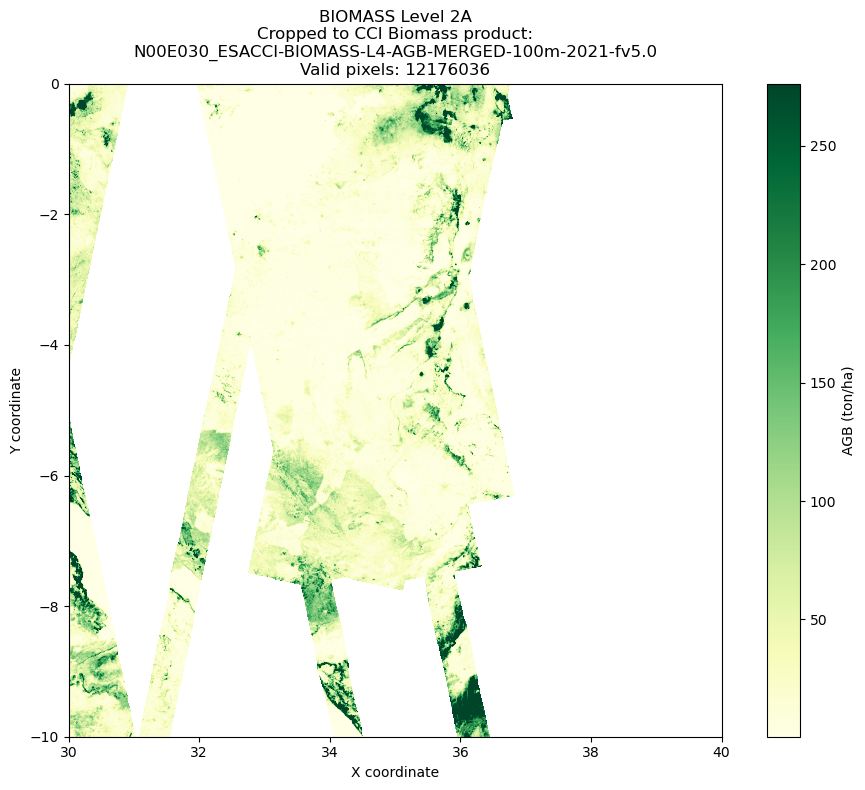

1 N00E040_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


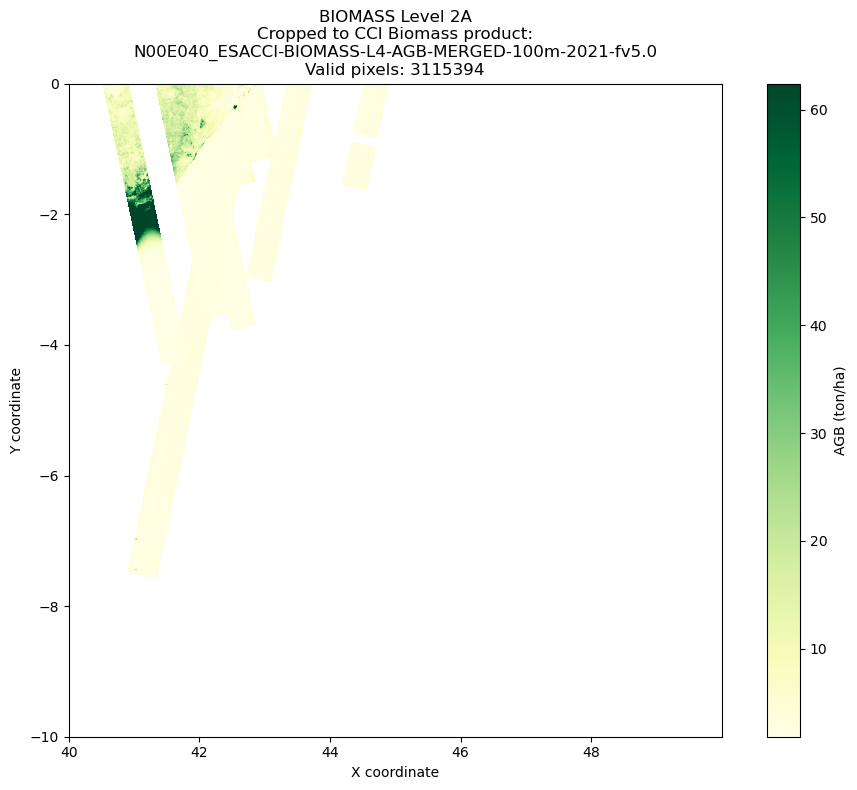

2 N00E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


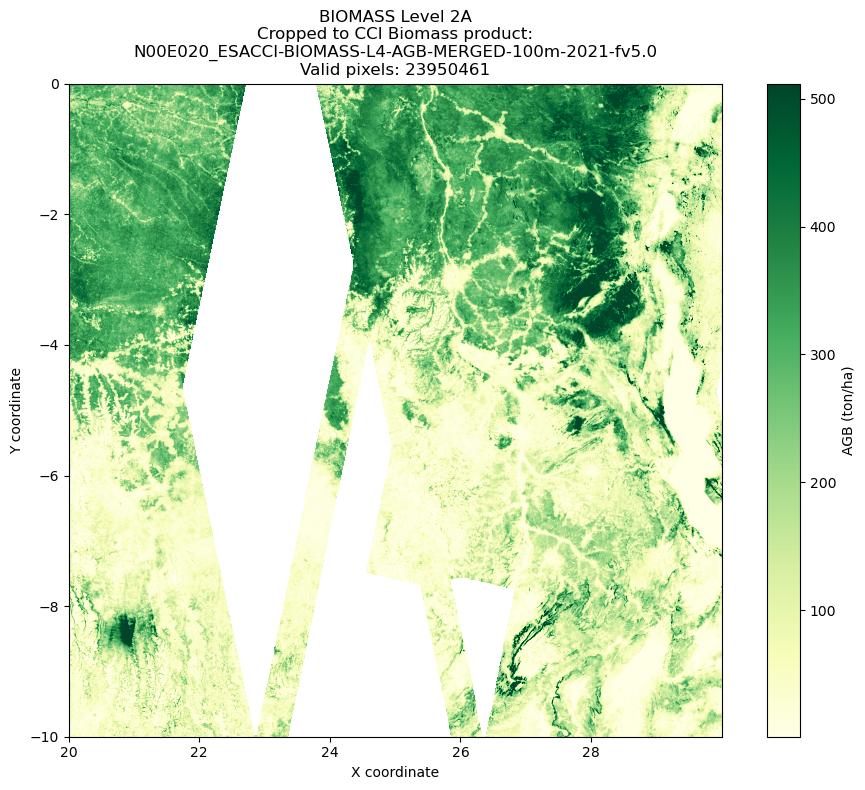

3 N00E010_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


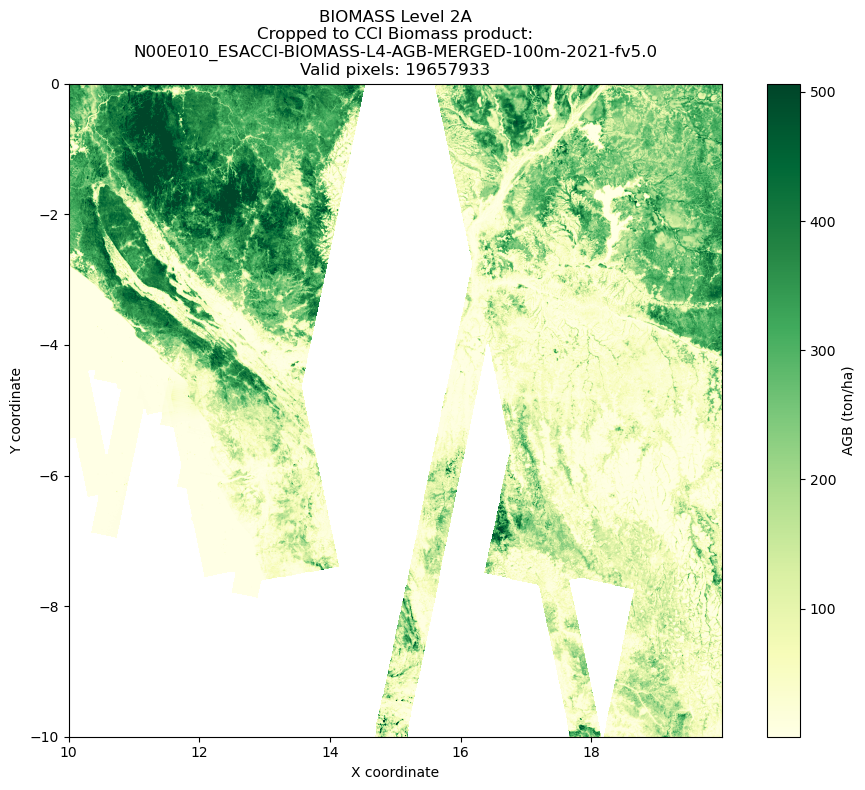

4 N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


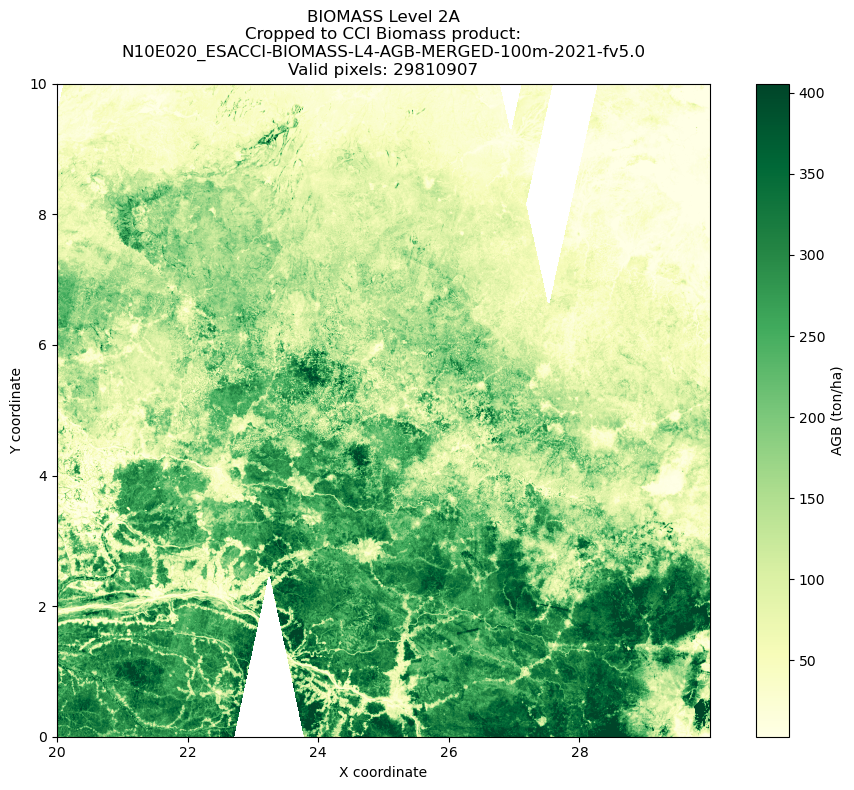

5 N20E000_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 2850 x 3836


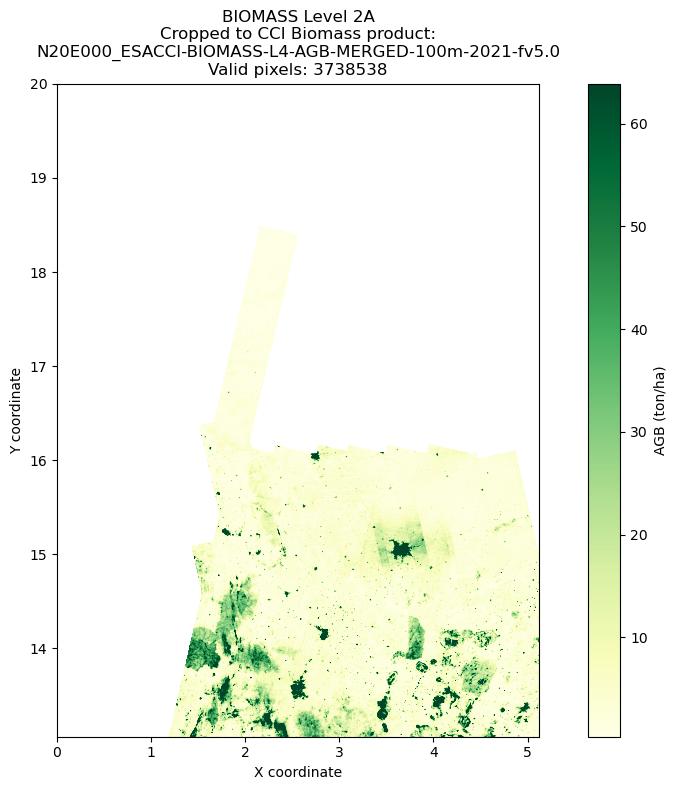

6 N20E030_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 3836


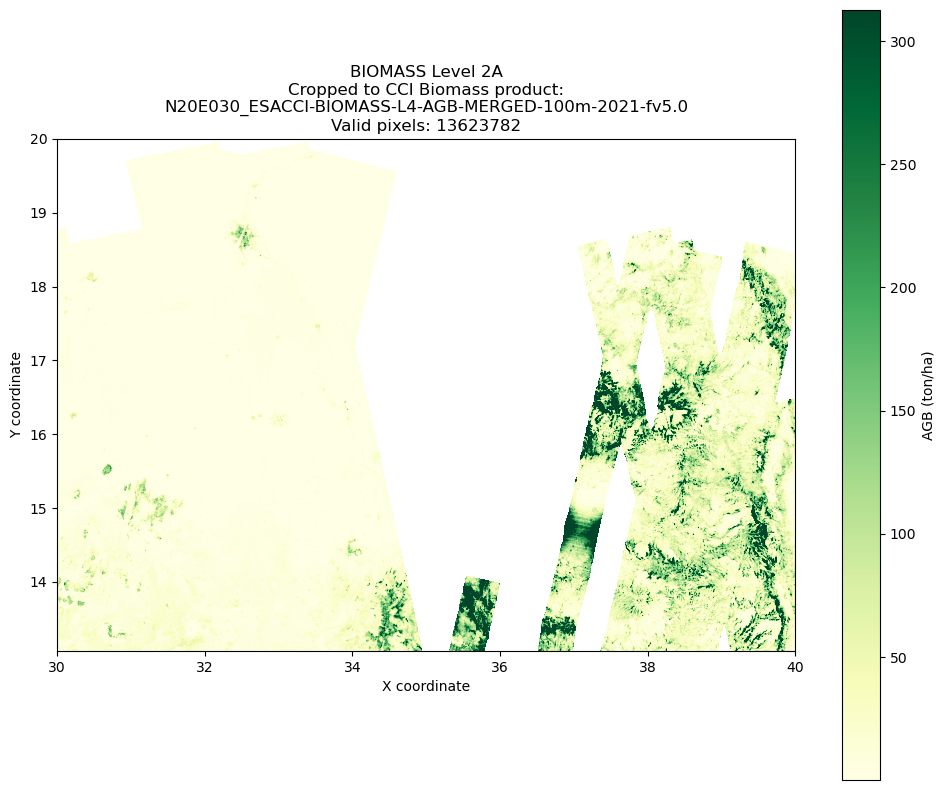

7 N20E040_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 3836


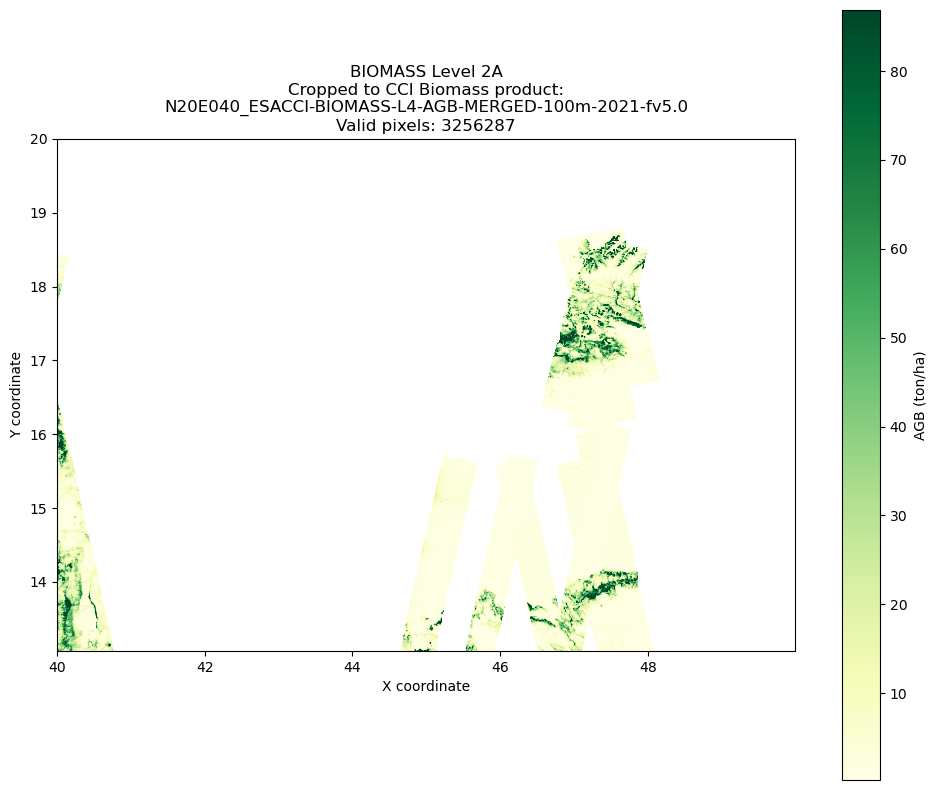

8 N20E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 3836


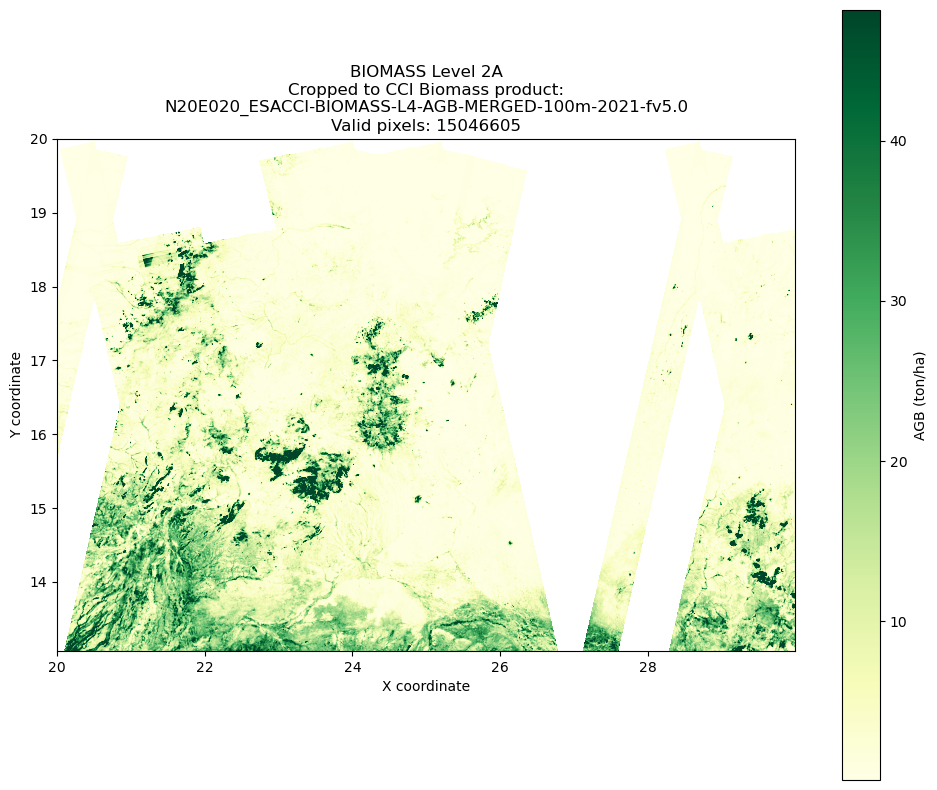

9 S10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 1344


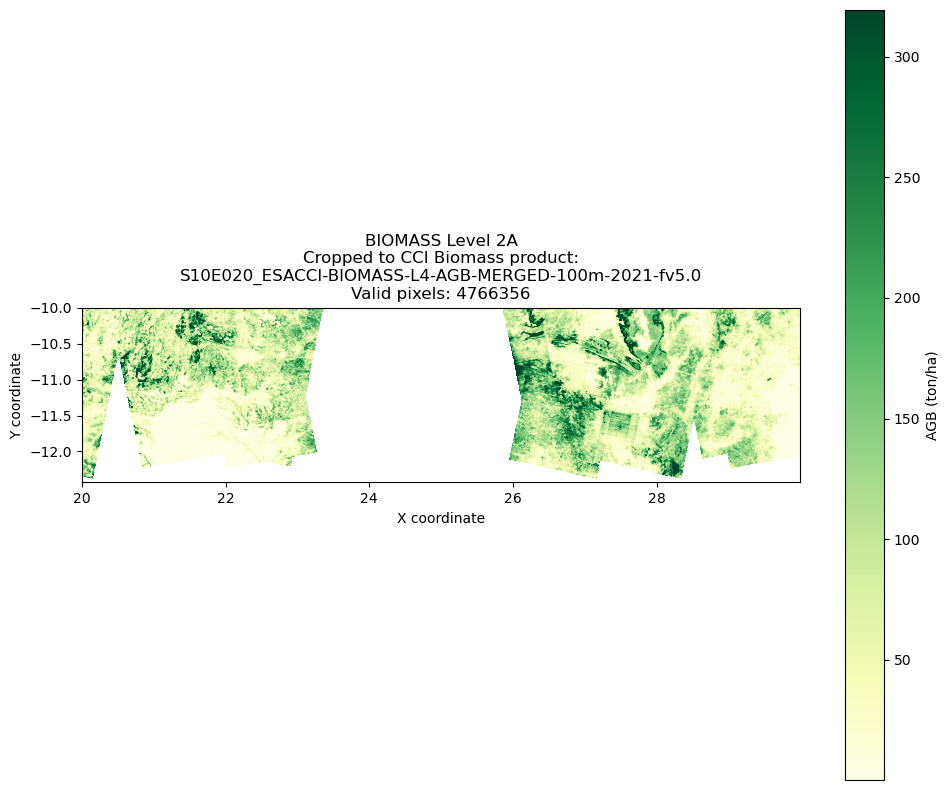

10 S10E010_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 1344


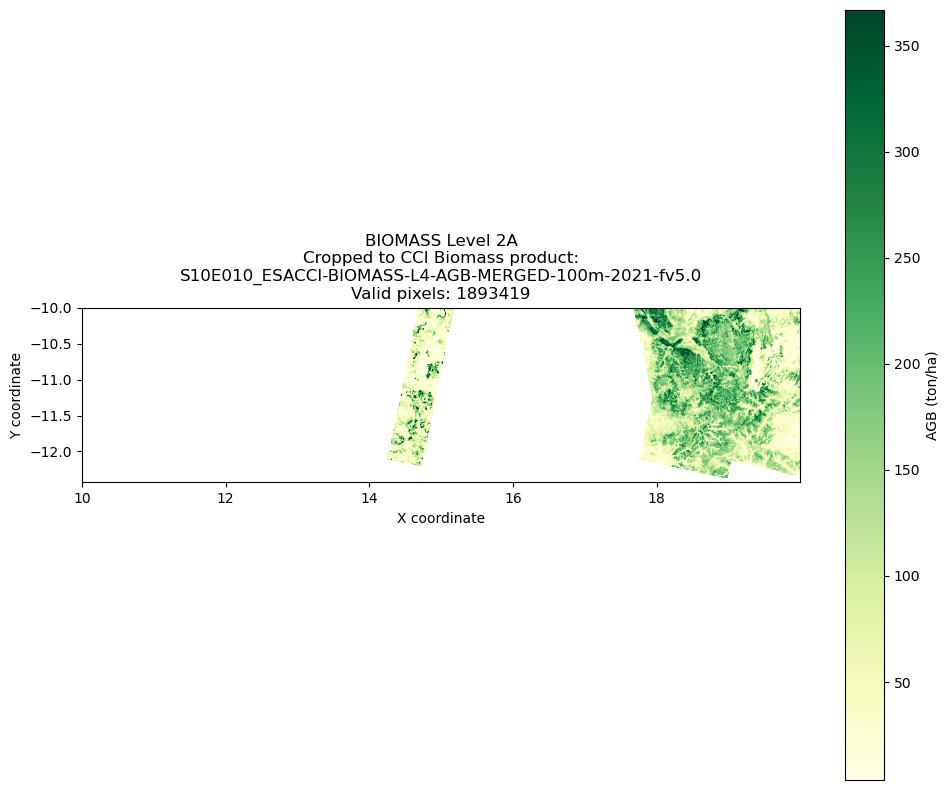

11 N10E000_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 2850 x 5529


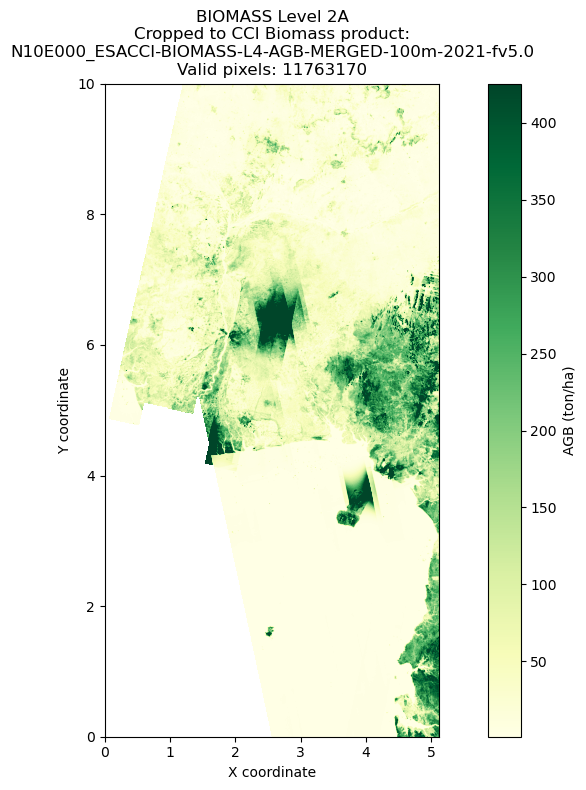

12 N10E040_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


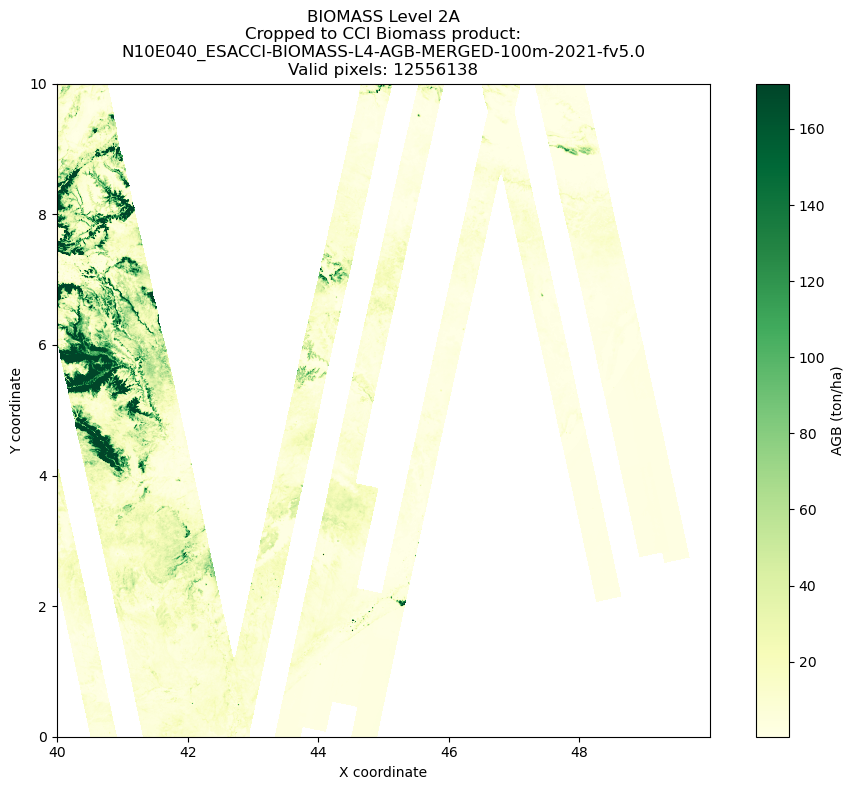

13 N20E050_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 2007 x 3836


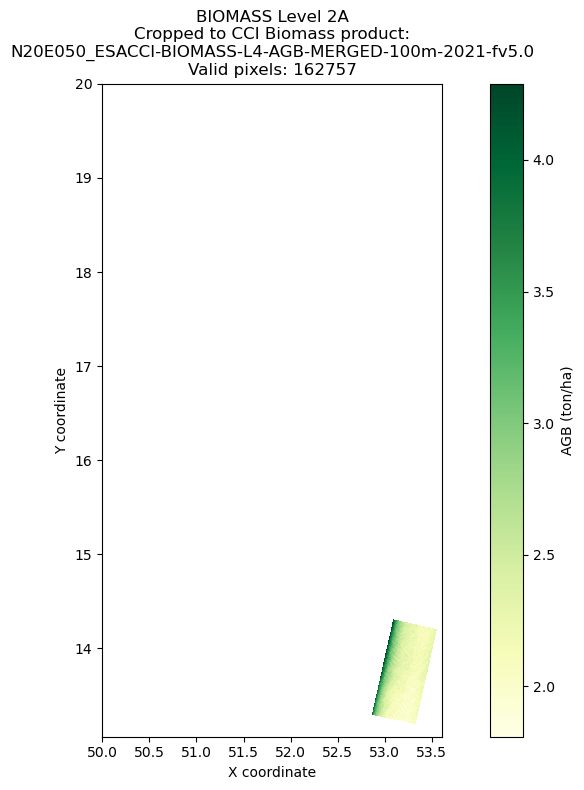

14 S10E050_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 2007 x 1344
The selected zone contains no valid pixels
CCI Biomass Product ID: S10E050_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
15 N00E000_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 2850 x 5529


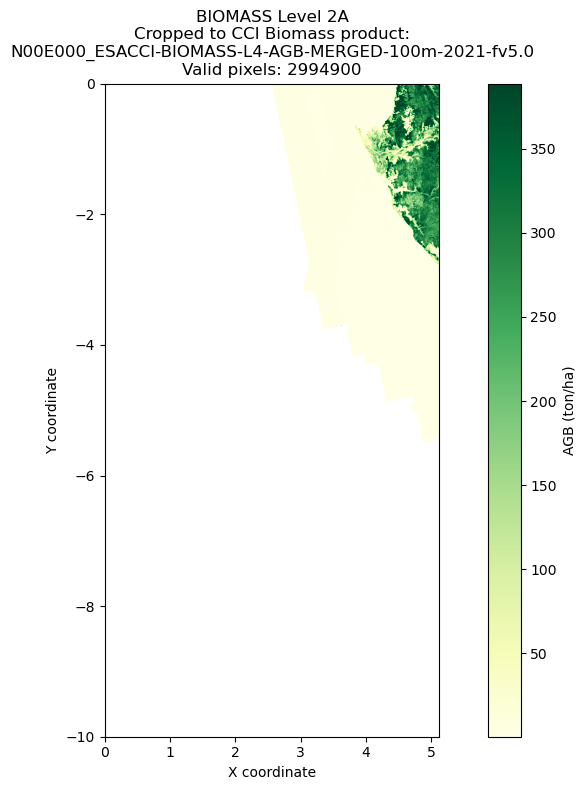

16 N10E030_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


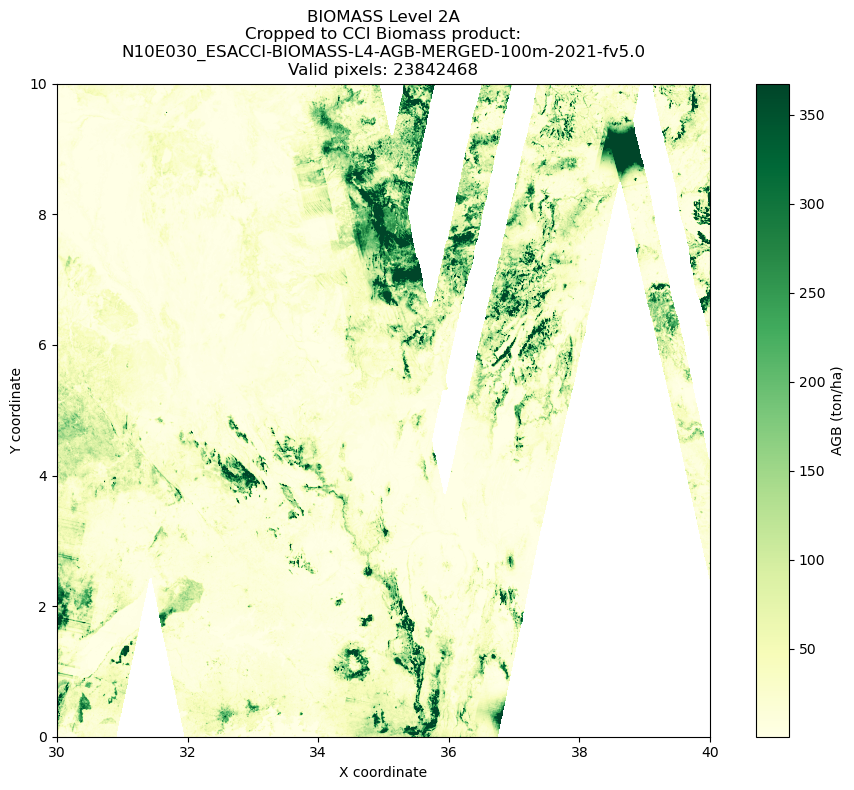

17 N10E050_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 2007 x 5529


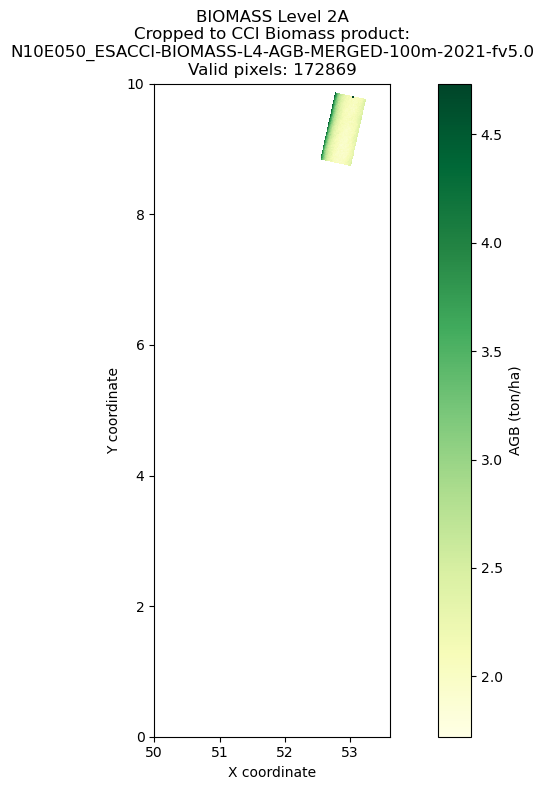

18 N10E010_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 5529


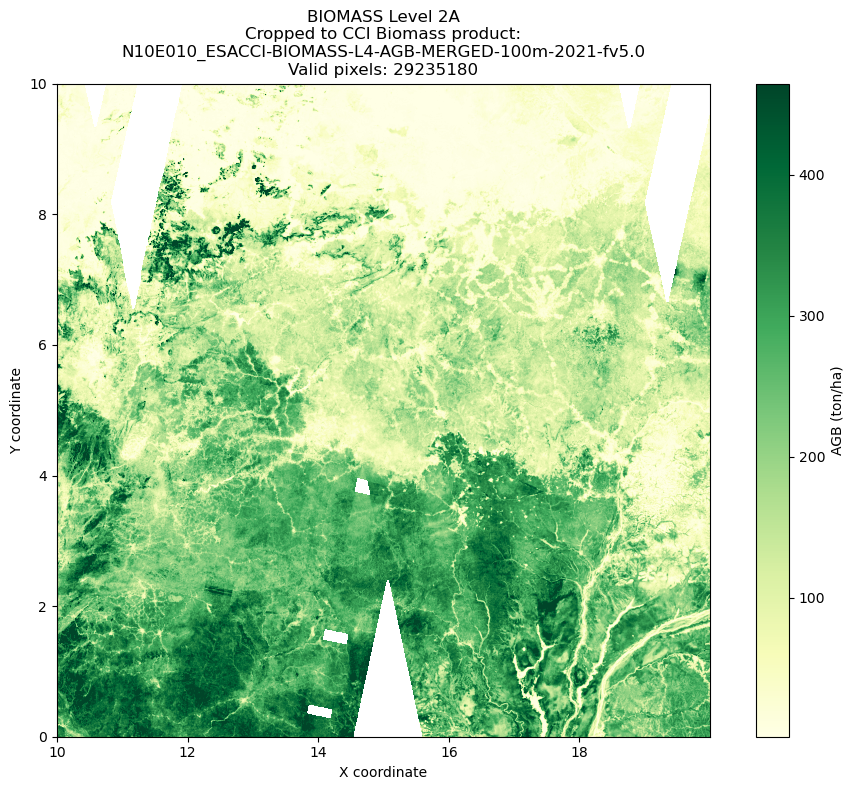

19 N20E010_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 3836


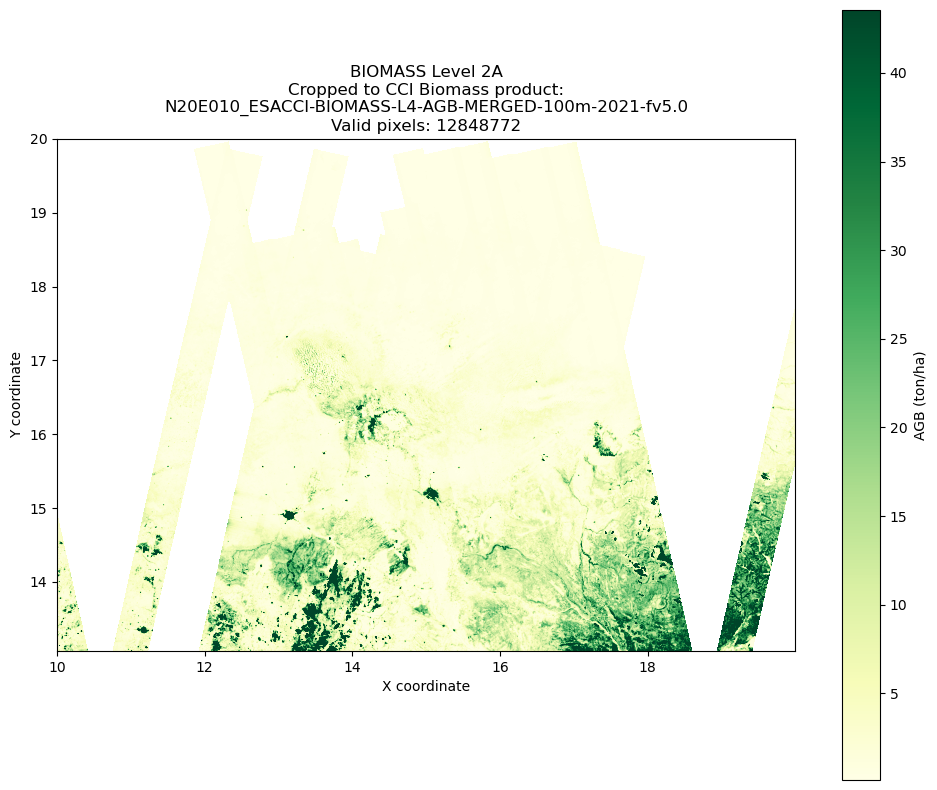

20 S10E040_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 1344
The selected zone contains no valid pixels
CCI Biomass Product ID: S10E040_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
21 S10E030_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0
Original size: 27103 x 16237
Cropped size: 5562 x 1344


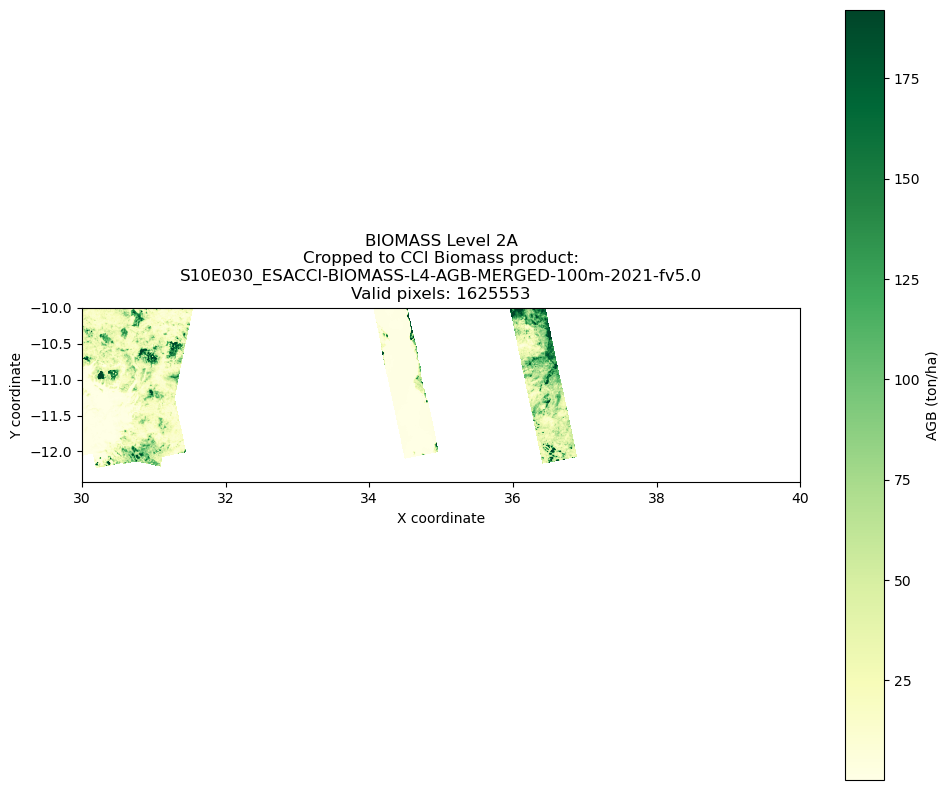

In [56]:
for i, row in gdf.iterrows():
    prod_id = row['product_id']
    minx, miny, maxx, maxy = row['geometry'].bounds
    print(i, prod_id)
    # Replace these example coordinates with your desired zone
    left = minx
    bottom = miny
    right = maxx
    top = maxy
    with rio.open(tif_path) as src:
        # Convert map coordinates into a pixel window
        window = from_bounds(
            left, bottom, right, top,
            transform=src.transform
        )
        # Align the window to whole pixels
        window = window.round_offsets().round_lengths()
        # Crop the raster
        cropped = src.read(1, window=window, masked=True)
        # Update the spatial transform for the cropped raster
        cropped_transform = src.window_transform(window)
        print("Original size:", src.width, "x", src.height)
        print("Cropped size:", cropped.shape[1], "x", cropped.shape[0])
        # Calculate the correct map extent for the cropped zone
        extent = plotting_extent(cropped, cropped_transform)
        
        # Convert masked pixels to NaN for display
        cropped_data = cropped.filled(np.nan)
        
        valid = cropped_data[np.isfinite(cropped_data)]
        valid_pxs = valid.size
        gdf.at[i,'Valid_pixels'] = valid_pxs
        # if valid.size > 0:
        if valid_pxs > 0:    
            #raise ValueError("The selected zone contains no valid pixels.")
        
            vmin, vmax = np.percentile(valid, [2, 98])
            # vmin, vmax = np.nanmin(valid), np.nanmax(valid)
            fig, ax = plt.subplots(figsize=(10, 8))
            # gpd.GeoSeries([row['geometry']]).plot(
            #     ax=ax, 
            #     color='blue', 
            #     edgecolor='black', 
            #     alpha=0.5
            # )
            im = ax.imshow(
                cropped_data,
                extent=extent,
                origin="upper",
                cmap="YlGn",
                vmin=vmin,
                vmax=vmax
            )
            
            cbar = plt.colorbar(im, ax=ax)
            cbar.set_label("AGB (ton/ha)")
            
            ax.set_title(f"BIOMASS Level 2A\nCropped to CCI Biomass product:\n{prod_id}\nValid pixels: {valid_pxs}")
            ax.set_xlabel("X coordinate")
            ax.set_ylabel("Y coordinate")
            
            plt.tight_layout()
            plt.show()
        else: 
            print(f'The selected zone contains no valid pixels\nCCI Biomass Product ID: {prod_id}')

## 5. Select the AOI based on the maximum numer of valid pixels

In [57]:
# Get the area with the most valid pixels
idx_max_px = np.argmax(gdf['Valid_pixels'])
prod_id = gdf.loc[idx_max_px, 'product_id']
item = gdf.loc[idx_max_px, 'item']
minx, miny, maxx, maxy = gdf.loc[idx_max_px,'geometry'].bounds
print(prod_id, item)
minx, miny, maxx, maxy

N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0 <Item id=N10E020_ESACCI-BIOMASS-L4-AGB-MERGED-100m-2021-fv5.0>


(20.0, 0.0, 30.0, 10.0)

## 6. Crop the AGB LA2 Congo map based on the AOI

In [58]:
# Replace these example coordinates with your desired zone
left = minx
bottom = miny
right = maxx
top = maxy

with rio.open(tif_path) as src:
    meta = src.meta
    # Convert map coordinates into a pixel window
    window = from_bounds(
        left, bottom, right, top,
        transform=src.transform
    )
    # Align the window to whole pixels
    window = window.round_offsets().round_lengths()
    # Crop the raster
    cropped = src.read(1, window=window, masked=True)
    # Update the spatial transform for the cropped raster
    cropped_transform = src.window_transform(window)
    print("Original size:", src.width, "x", src.height)
    print("Cropped size:", cropped.shape[1], "x", cropped.shape[0])
    # Calculate the correct map extent for the cropped zone
    extent = plotting_extent(cropped, cropped_transform)
    
    # Convert masked pixels to NaN for display
    cropped_data = cropped.filled(np.nan)

Original size: 27103 x 16237
Cropped size: 5562 x 5529


In [59]:
out_meta = src.meta
cropped_data_nx = np.expand_dims(cropped_data, axis=0)
cropped_data_nx.shape

(1, 5529, 5562)

In [61]:
out_meta.update({"driver": "GTiff",
                 "height": cropped_data_nx.shape[1],
                 "width": cropped_data_nx.shape[2],
                 "transform": cropped_transform,
                 "count":1})

with rio.open(f"agbd_map_L2A_cropped_{prod_id}.tif", "w", **out_meta) as dest:
    dest.write(cropped_data_nx)

In [62]:
# Save gdf with the valid pixels ifno
gdf.to_csv('CCI_biomass_products_Congo_valid_pxs.csv', index=False)